# Brain MRI image preprocessing

This notebook audits the class folders in `scan_images`, creates a reproducible stratified image-level 70/15/15 train/validation/test split, and writes preprocessed copies under `processed_scan_images_mri`. Original files are not modified.

The pipeline composites transparent pixels onto black, converts to grayscale (then repeats the grayscale channel three times for ImageNet-style models), optionally crops dark background and applies CLAHE or mild Gaussian smoothing, resizes with aspect ratio preserved, and computes z-score normalization statistics from training foreground pixels only. Training augmentations and an optional weighted sampler are defined at the end.

**Check the grayscale preview before training:** these local PNGs are RGBA and appear colorized. Grayscale conversion can discard information encoded in the color map; compare grayscale against the original color images if the colors are meaningful. The provided split is by image, not patient, so related slices may cross splits and make evaluation optimistic. Patient IDs are not available in the local folder structure.

Readable images: 3064
Image counts per class before preprocessing:
  1: 708
  2: 1426
  3: 930
Image dimensions: {(512, 512): 3049, (256, 256): 15}
Image modes: {'RGBA': 3064}


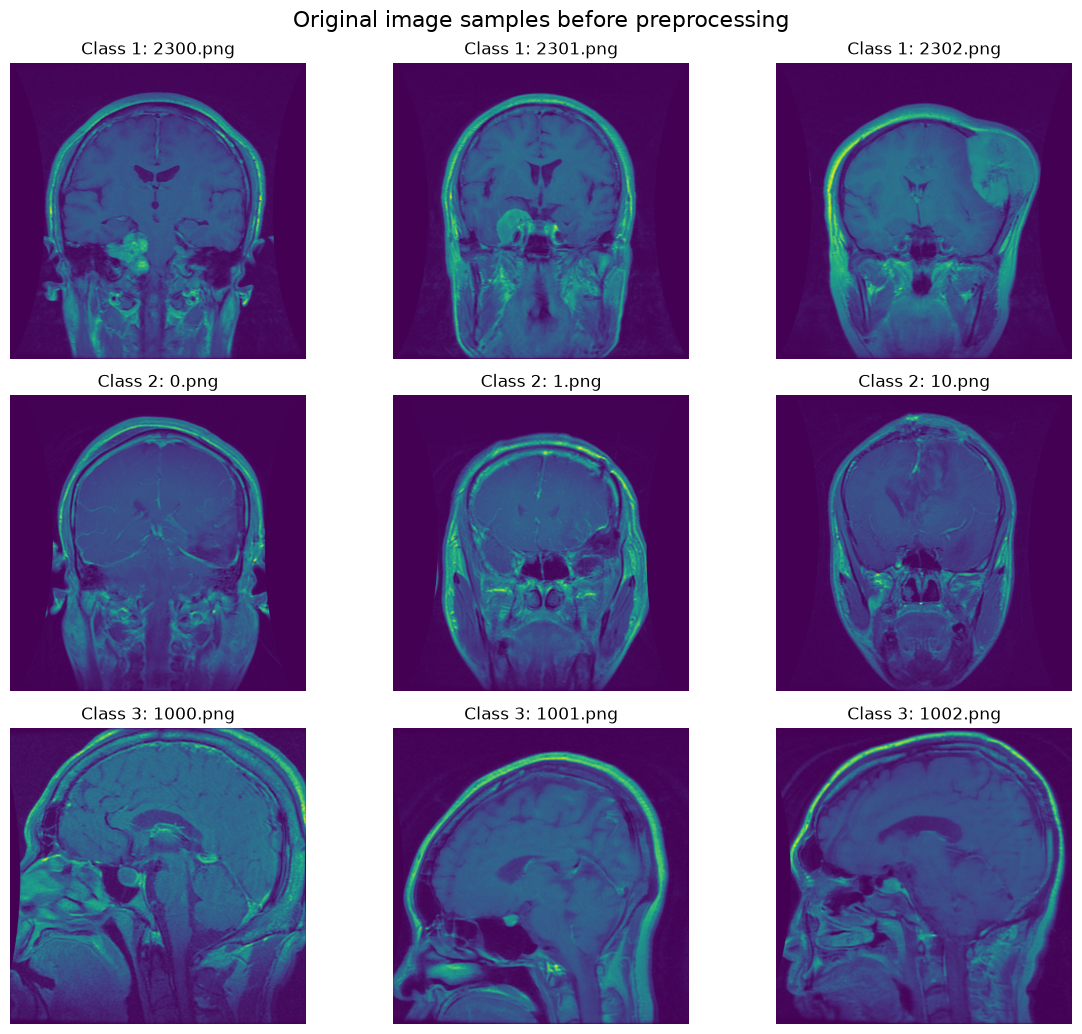

In [1]:
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps, UnidentifiedImageError

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "scan_images").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

SOURCE_DIR = PROJECT_ROOT / "scan_images"
OUTPUT_DIR = PROJECT_ROOT / "processed_scan_images_mri"
IMAGE_SIZE = (224, 224)
SAMPLE_IMAGES_PER_CLASS = 3
RANDOM_SEED = 42
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

# Conservative preprocessing options. Blur is off by default to avoid losing texture.
CROP_DARK_BACKGROUND = True
USE_CLAHE = True
USE_GAUSSIAN_BLUR = False
BACKGROUND_THRESHOLD = 8
CROP_MARGIN_FRACTION = 0.05

if not SOURCE_DIR.is_dir():
    raise FileNotFoundError(f"Could not find the dataset folder: {SOURCE_DIR}")

class_dirs = sorted(path for path in SOURCE_DIR.iterdir() if path.is_dir())
if not class_dirs:
    raise ValueError(f"No class folders found in {SOURCE_DIR}")

records = []
invalid_files = []
for class_dir in class_dirs:
    for image_path in sorted(class_dir.iterdir()):
        if not image_path.is_file() or image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        try:
            with Image.open(image_path) as image:
                image.verify()
            with Image.open(image_path) as image:
                image = ImageOps.exif_transpose(image)
                records.append({
                    "path": image_path,
                    "label": class_dir.name,
                    "size": image.size,
                    "mode": image.mode,
                })
        except (UnidentifiedImageError, OSError) as exc:
            invalid_files.append((image_path, str(exc)))

if not records:
    raise ValueError(f"No readable images found in {SOURCE_DIR}")

print(f"Readable images: {len(records)}")
images_before_by_class = Counter(record["label"] for record in records)
print("Image counts per class before preprocessing:")
for class_dir in class_dirs:
    print(f"  {class_dir.name}: {images_before_by_class[class_dir.name]}")
print(f"Image dimensions: {dict(Counter(record['size'] for record in records))}")
print(f"Image modes: {dict(Counter(record['mode'] for record in records))}")
if invalid_files:
    print(f"\nSkipped {len(invalid_files)} unreadable image(s):")
    for image_path, error in invalid_files:
        print(f"  {image_path}: {error}")

preview_records = {
    class_dir.name: [record for record in records if record["label"] == class_dir.name][:SAMPLE_IMAGES_PER_CLASS]
    for class_dir in class_dirs
}
preview_columns = max(len(samples) for samples in preview_records.values())
fig, axes = plt.subplots(
    len(class_dirs), preview_columns,
    figsize=(4 * preview_columns, 3.5 * len(class_dirs)),
    squeeze=False,
)
for row, class_dir in enumerate(class_dirs):
    for column in range(preview_columns):
        axis = axes[row, column]
        if column < len(preview_records[class_dir.name]):
            record = preview_records[class_dir.name][column]
            with Image.open(record["path"]) as source_image:
                rgba = ImageOps.exif_transpose(source_image).convert("RGBA")
                black_background = Image.new("RGBA", rgba.size, (0, 0, 0, 255))
                original = Image.alpha_composite(black_background, rgba).convert("RGB")
            axis.imshow(original)
            axis.set_title(f"Class {class_dir.name}: {record['path'].name}")
        axis.axis("off")
fig.suptitle("Original image samples before preprocessing", fontsize=16)
fig.tight_layout()
plt.show()

## Split and preprocess

The contour crop targets the largest component above a near-black threshold and adds a margin; if no plausible component is found, the full image is retained. CLAHE is applied to grayscale using a conservative clip limit. Padding is added after resize, without cropping or stretching. The split is stratified by class but not grouped by patient because patient identifiers are unavailable.

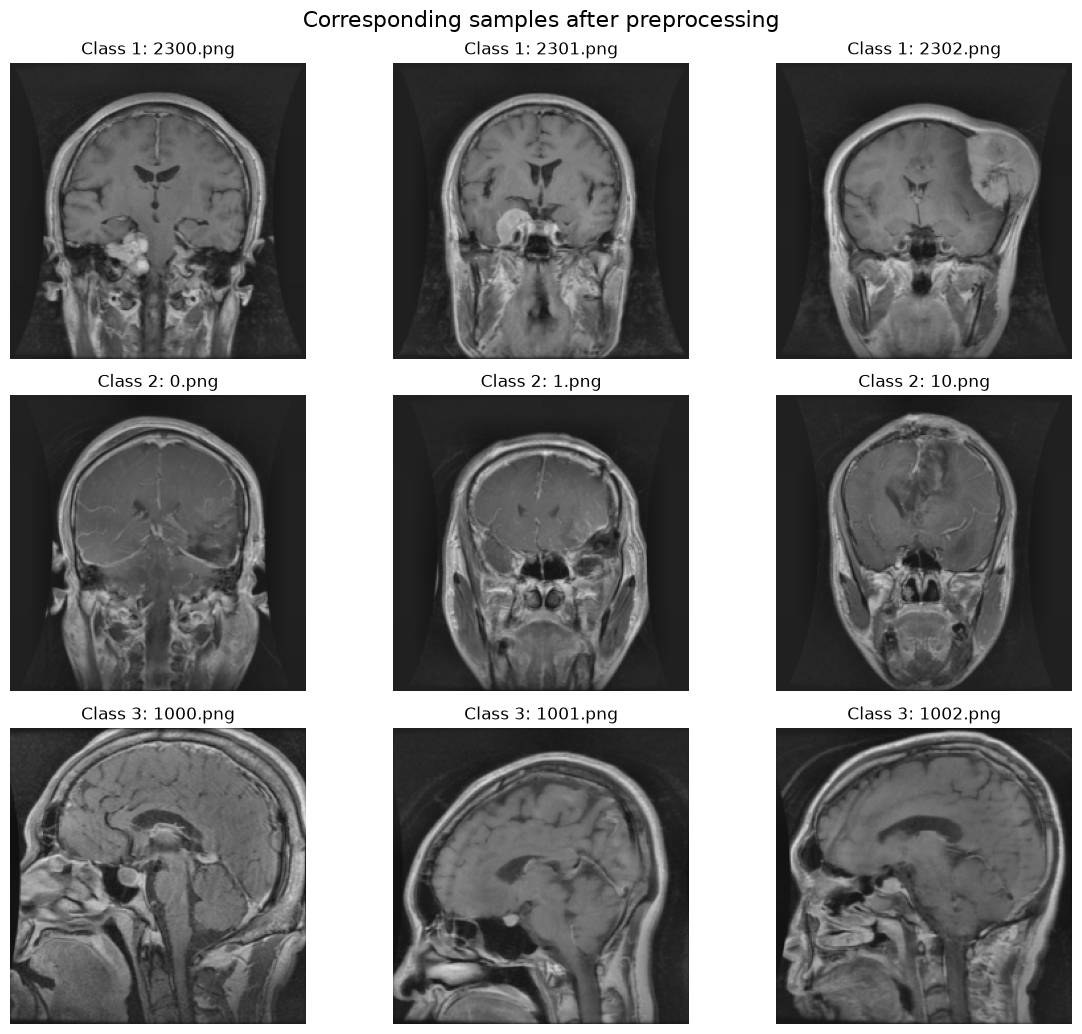


Processed images saved under: /Users/Oshadi/MSc/7004ENG_Individual_Project/OVST/Sample_Projects/Brain-scan/processed_scan_images_mri
Manifest saved to: /Users/Oshadi/MSc/7004ENG_Individual_Project/OVST/Sample_Projects/Brain-scan/processed_scan_images_mri/manifest.csv
Image counts per class after preprocessing:
  1: 708
  2: 1426
  3: 930

Image counts per class after splitting:
Class            Train    Validation      Test     Total
1                  495           106       107       708
2                  998           214       214      1426
3                  651           140       139       930
train (2144 images): {'1': 495, '2': 998, '3': 651}
validation (460 images): {'1': 106, '2': 214, '3': 140}
test (460 images): {'1': 107, '2': 214, '3': 139}

Training foreground channel mean ([0, 1] scale): [0.2822 0.2822 0.2822]
Training foreground channel std: [0.1643 0.1643 0.1643]


In [2]:
import csv
import json
import json

from sklearn.model_selection import train_test_split

train_records, remainder_records = train_test_split(
    records,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=[record["label"] for record in records],
)
validation_records, test_records = train_test_split(
    remainder_records,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=[record["label"] for record in remainder_records],
)
split_records = {
    "train": train_records,
    "validation": validation_records,
    "test": test_records,
}

def preprocess_image(image_path):
    """Return a three-channel grayscale MRI image resized without distortion."""
    with Image.open(image_path) as source_image:
        rgba = ImageOps.exif_transpose(source_image).convert("RGBA")
        background = Image.new("RGBA", rgba.size, (0, 0, 0, 255))
        rgb = Image.alpha_composite(background, rgba).convert("RGB")
        gray = cv2.cvtColor(np.asarray(rgb), cv2.COLOR_RGB2GRAY)

    if CROP_DARK_BACKGROUND:
        _, binary = cv2.threshold(
            gray, BACKGROUND_THRESHOLD, 255, cv2.THRESH_BINARY
        )
        contours, _ = cv2.findContours(
            binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        if contours:
            x, y, width, height = cv2.boundingRect(max(contours, key=cv2.contourArea))
            if width * height >= 0.15 * gray.shape[0] * gray.shape[1]:
                margin = max(4, int(CROP_MARGIN_FRACTION * max(width, height)))
                x0 = max(0, x - margin)
                y0 = max(0, y - margin)
                x1 = min(gray.shape[1], x + width + margin)
                y1 = min(gray.shape[0], y + height + margin)
                gray = gray[y0:y1, x0:x1]

    if USE_CLAHE:
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        gray = clahe.apply(gray)
    if USE_GAUSSIAN_BLUR:
        gray = cv2.GaussianBlur(gray, (3, 3), sigmaX=0)

    image = Image.fromarray(gray)
    image.thumbnail(IMAGE_SIZE, Image.Resampling.BILINEAR)
    canvas = Image.new("L", IMAGE_SIZE, 0)
    offset = ((IMAGE_SIZE[0] - image.width) // 2, (IMAGE_SIZE[1] - image.height) // 2)
    canvas.paste(image, offset)
    gray_array = np.asarray(canvas)
    rgb_array = np.repeat(gray_array[:, :, np.newaxis], 3, axis=2)
    return Image.fromarray(rgb_array, mode="RGB")

fig, axes = plt.subplots(
    len(class_dirs), preview_columns,
    figsize=(4 * preview_columns, 3.5 * len(class_dirs)),
    squeeze=False,
)
for row, class_dir in enumerate(class_dirs):
    for column in range(preview_columns):
        axis = axes[row, column]
        if column < len(preview_records[class_dir.name]):
            record = preview_records[class_dir.name][column]
            axis.imshow(preprocess_image(record["path"]))
            axis.set_title(f"Class {class_dir.name}: {record['path'].name}")
        axis.axis("off")
fig.suptitle("Corresponding samples after preprocessing", fontsize=16)
fig.tight_layout()
plt.show()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
manifest_rows = []
channel_sum = np.zeros(3, dtype=np.float64)
channel_squared_sum = np.zeros(3, dtype=np.float64)
foreground_pixel_count = 0

for split_name, split in split_records.items():
    for record in split:
        processed_image = preprocess_image(record["path"])
        output_path = OUTPUT_DIR / split_name / record["label"] / f"{record['path'].stem}.png"
        output_path.parent.mkdir(parents=True, exist_ok=True)
        processed_image.save(output_path, format="PNG")

        if split_name == "train":
            pixels = np.asarray(processed_image, dtype=np.float32) / 255.0
            foreground_mask = np.any(pixels > 0, axis=2)
            foreground_pixels = pixels[foreground_mask]
            channel_sum += foreground_pixels.sum(axis=0)
            channel_squared_sum += np.square(foreground_pixels).sum(axis=0)
            foreground_pixel_count += len(foreground_pixels)

        manifest_rows.append({
            "source_path": str(record["path"].relative_to(PROJECT_ROOT)),
            "split": split_name,
            "label": record["label"],
            "processed_path": str(output_path.relative_to(PROJECT_ROOT)),
        })

manifest_path = OUTPUT_DIR / "manifest.csv"
with manifest_path.open("w", newline="", encoding="utf-8") as manifest_file:
    writer = csv.DictWriter(
        manifest_file,
        fieldnames=["source_path", "split", "label", "processed_path"],
    )
    writer.writeheader()
    writer.writerows(manifest_rows)

if foreground_pixel_count == 0:
    raise ValueError("No non-background training pixels found for normalization.")
channel_mean = channel_sum / foreground_pixel_count
channel_std = np.sqrt(
    np.maximum(channel_squared_sum / foreground_pixel_count - channel_mean**2, 0)
)
channel_std = np.maximum(channel_std, 1e-6)
normalization_path = OUTPUT_DIR / "normalization.json"
with normalization_path.open("w", encoding="utf-8") as normalization_file:
    json.dump(
        {"mean": channel_mean.tolist(), "std": channel_std.tolist()},
        normalization_file,
        indent=2,
    )

images_after_by_class = Counter(row["label"] for row in manifest_rows)
print(f"\nProcessed images saved under: {OUTPUT_DIR}")
print(f"Manifest saved to: {manifest_path}")
print(f"Normalization statistics saved to: {normalization_path}")
print("Image counts per class after preprocessing:")
for class_dir in class_dirs:
    print(f"  {class_dir.name}: {images_after_by_class[class_dir.name]}")
print("\nImage counts per class after splitting:")
print(f"{'Class':<12}{'Train':>10}{'Validation':>14}{'Test':>10}{'Total':>10}")
for class_dir in class_dirs:
    class_split_counts = {
        split_name: sum(record["label"] == class_dir.name for record in split)
        for split_name, split in split_records.items()
    }
    total = sum(class_split_counts.values())
    print(
        f"{class_dir.name:<12}{class_split_counts['train']:>10}"
        f"{class_split_counts['validation']:>14}{class_split_counts['test']:>10}{total:>10}"
    )
for split_name, split in split_records.items():
    counts = Counter(record["label"] for record in split)
    print(f"{split_name} ({len(split)} images): {dict(sorted(counts.items()))}")
print(f"\nTraining foreground channel mean ([0, 1] scale): {channel_mean.round(4)}")
print(f"Training foreground channel std: {channel_std.round(4)}")

## Training transforms and class balancing

Random augmentation is applied only to training images. The example uses mild rotation, translation, scale, horizontal flips, brightness/contrast changes, and occasional low-amplitude Gaussian noise. Vertical flipping is omitted to avoid unrealistic anatomy. A weighted sampler is prepared to reduce class imbalance; use it instead of `shuffle=True`, and do not initially combine it with class-weighted loss.

In [3]:
import torch
from torch.utils.data import WeightedRandomSampler
from torchvision import transforms
from torchvision.datasets import ImageFolder

class RandomGaussianNoise:
    def __init__(self, probability=0.15, standard_deviation=0.01):
        self.probability = probability
        self.standard_deviation = standard_deviation

    def __call__(self, tensor):
        if torch.rand(()) < self.probability:
            noise = torch.randn_like(tensor) * self.standard_deviation
            return (tensor + noise).clamp(0.0, 1.0)
        return tensor

normalization = transforms.Normalize(
    mean=channel_mean.tolist(),
    std=channel_std.tolist(),
)

train_transform = transforms.Compose([
    transforms.RandomAffine(
        degrees=10,
        translate=(0.02, 0.02),
        scale=(0.95, 1.05),
        fill=0,
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.10, contrast=0.10),
    transforms.ToTensor(),
    RandomGaussianNoise(),
    normalization,
])
evaluation_transform = transforms.Compose([
    transforms.ToTensor(),
    normalization,
])

train_dataset = ImageFolder(OUTPUT_DIR / "train", transform=train_transform)
validation_dataset = ImageFolder(OUTPUT_DIR / "validation", transform=evaluation_transform)
test_dataset = ImageFolder(OUTPUT_DIR / "test", transform=evaluation_transform)

train_class_counts = Counter(train_dataset.targets)
sample_weights = [1.0 / train_class_counts[target] for target in train_dataset.targets]
train_sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True,
)

print(f"Classes: {train_dataset.classes}")
print(f"Training class counts: {dict(sorted(train_class_counts.items()))}")
print("Datasets and transforms are ready.")
print("Build the training DataLoader with sampler=train_sampler and do not set shuffle=True.")
print("Use evaluation_transform for validation/test; no augmentation is applied to those sets.")

Classes: ['1', '2', '3']
Training class counts: {0: 495, 1: 998, 2: 651}
Datasets and transforms are ready.
Build the training DataLoader with sampler=train_sampler and do not set shuffle=True.
Use evaluation_transform for validation/test; no augmentation is applied to those sets.
